# 11 Hybrids: when a model should say it is not sure

*Teaching material. Not for clinical use.*

Fifty physicians worked through written clinical vignettes, with and without a language model to consult. With the model their median diagnostic reasoning score was 76%; without it, 74%: a difference of 2 points (-4 to 8). The model on its own scored 92%, 16 points above the physicians without it (2 to 30) (E-110).

**Before reading on, guess.** What does that say about putting tools and people together?

- The model was not much help
- The physicians were the weak link
- Something was lost where the two met
- Fifty physicians are too few to say anything

Write the guess down. It is not marked, and the answer comes in the diagnosis section below. Keep the limits beside it: fifty physicians, written vignettes and no patients. Nothing here says that a language model diagnoses better than a doctor.

In [1]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline, thread
from inference_labs.lenses import bayesian, decision, hybrids, rules

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID = "#7f2704", "#d9d9d9", "#08306b"   # needs intervention, does not, published figure
PALE = "#6baed6"                                      # a second series: lighter, and drawn hollow or hatched
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)

# 100,000 synthetic casualties, seed 42, military cohort, every stream. Every result on them is a mechanism.
observed, truth = baseline.generator_sample()
need = truth["needs_lsi"].to_numpy(bool)
battle = (observed["stream"] == "battle").to_numpy()

## The idea, before any medicine

A forecaster who must say "rain" or "dry" every morning will be wrong on the doubtful days, and nothing in the forecast warns you which days those are. Allow her to say "rain or dry: cannot tell" on the doubtful days, and hold her to being right about what she says on nine days in ten, and she says something useful every morning: one answer when she is sure, a warning when she is not. Her forecasting has not improved. It has learnt to show its doubt.

**Plain.** A tool that gives one answer hides its doubt. A prediction set gives one answer when the tool is sure and a short list when it is not, sized so that the list holds the truth for a stated share of cases. For triage, "need or no need: look again" is a legitimate answer. The share is an average over cases like the ones the set was checked on: it does not promise anything for one casualty, or for casualties of a different kind.

**Developer.** Split conformal prediction wraps a model that is already fitted. Score how badly each of a set of new, labelled calibration cases fits its own label, take the score that a stated share of them stay under, and keep every label a new case scores within.

```python
p_cal = model_probability(calibration_cases)              # the model was fitted on other cases
scores = np.where(in_need, 1 - p_cal, p_cal)              # one minus the probability of the true label
q = np.sort(scores)[math.ceil((n + 1) * 0.90) - 1]        # the threshold
holds_need, holds_no_need = (1 - p_new) <= q, p_new <= q  # the new case's set
```

It costs one model, $n$ more labelled cases and one sort.

**Technical.** For a fitted model with probability $\hat p_y(x)$ of label $y$, define the nonconformity $s(x, y) = 1 - \hat p_y(x)$. On $n$ calibration cases take $\hat q$ as the $\lceil (n+1)(1-\alpha) \rceil$-th smallest $s(x_i, y_i)$ and return $C(x) = \{y : s(x, y) \le \hat q\}$. E-112 records what the method does: it wraps any trained model to output a set that contains the truth at a rate the user chooses, without assuming a distribution. The condition under which it does so is general knowledge about the method, not taken from that register entry: if the calibration cases and the new case are exchangeable, $P(Y \in C(X)) \ge 1 - \alpha$, on average over calibration sets and new cases, and not within any subgroup.

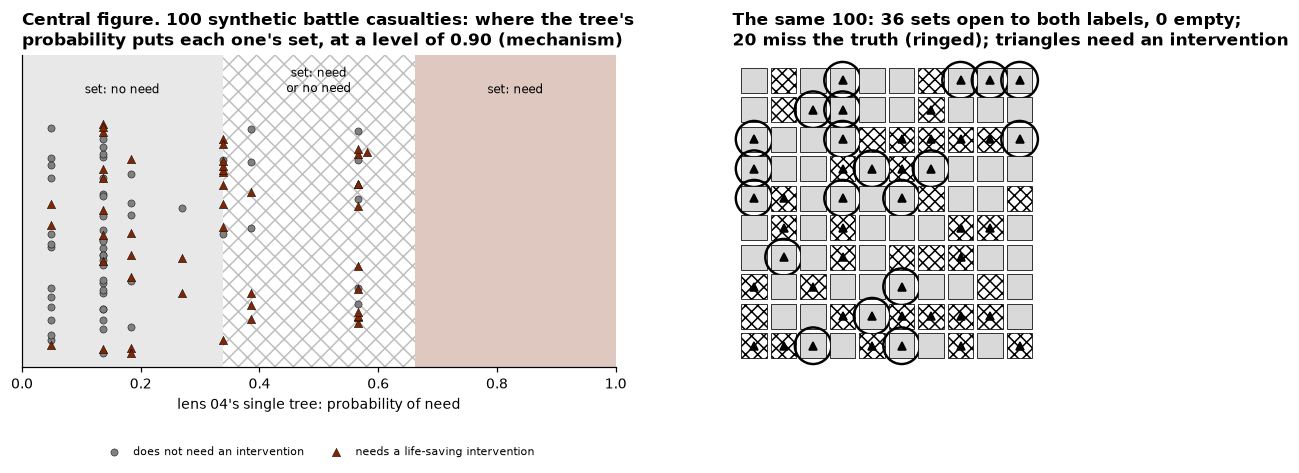

In [2]:
# Central figure: the envelopes. The control: change it and run the cell again.
LEVEL = 0.90     # the share of casualties whose set should hold the truth: 0.80, 0.85, 0.90, 0.95 or 0.99

env = hybrids.envelopes(LEVEL)
p, truth_need, has_need, has_no = env["probability"], env["need"], env["has_need"], env["has_no"]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
lo, hi = sorted((env["lower"], env["upper"]))
opens = env["lower"] <= env["upper"]       # below one half the threshold leaves the middle with an empty set
ax.axvspan(0, lo, color=LIGHT, alpha=0.6, linewidth=0)
ax.axvspan(lo, hi, facecolor="white", hatch="xx" if opens else None, edgecolor="grey", alpha=0.5, linewidth=0)
ax.axvspan(hi, 1, color=DARK, alpha=0.25, linewidth=0)
for x, words in ((lo / 2, "set: no need"), ((lo + hi) / 2, "set: need\nor no need" if opens else "set: empty"),
                 ((hi + 1) / 2, "set: need")):
    ax.text(x, 1.04, words, ha="center", va="bottom", fontsize=8)
rng = np.random.default_rng(1)
y = rng.uniform(0.05, 0.95, p.size)
ax.scatter(p[~truth_need], y[~truth_need], s=22, color="grey", edgecolor="black", linewidth=0.3,
           label="does not need an intervention")
ax.scatter(p[truth_need], y[truth_need], s=30, marker="^", color=DARK, edgecolor="black", linewidth=0.3,
           label="needs a life-saving intervention")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.2)
ax.set_yticks([])
ax.set_xlabel("lens 04's single tree: probability of need")
ax.legend(fontsize=7, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=2)
ax.set_title(f"Central figure. {env['n']} synthetic battle casualties: where the tree's\n"
             f"probability puts each one's set, at a level of {LEVEL:.2f} (mechanism)", loc="left")
covered = np.where(truth_need, has_need, has_no)
for k in range(env["n"]):
    r, c = divmod(k, 10)
    face = "white" if has_need[k] and has_no[k] else (DARK if has_need[k] else LIGHT)
    bx.add_patch(plt.Rectangle((c, 9 - r), 0.86, 0.86, facecolor=face, edgecolor="black", linewidth=0.5,
                               hatch="xxx" if has_need[k] and has_no[k] else None))
    if truth_need[k]:
        bx.plot(c + 0.43, 9 - r + 0.43, marker="^", color="white" if face == DARK else "black", markersize=5)
    if not covered[k]:
        bx.add_patch(plt.Circle((c + 0.43, 9 - r + 0.43), 0.62, fill=False, edgecolor="black", linewidth=1.6))
bx.set_xlim(-0.3, 10.3)
bx.set_ylim(-0.3, 10.3)
bx.set_aspect("equal")
bx.axis("off")
bx.set_title(f"The same {env['n']}: {env['both']} sets open to both labels, {env['empty']} empty;\n{env['missed']} miss "
             f"the truth (ringed); triangles need an intervention", loc="left")
plt.tight_layout()
plt.show()

Each mark on the left is one of the first hundred synthetic battle casualties of the evaluation sample, placed at lens 04's single tree's probability that it needs a life-saving intervention. The tree has eight leaves, so the probabilities fall on a few values. The shading shows what set each probability gets: low probabilities give "no need", high ones "need", and the middle opens into both. At the level of 0.90 the region for "need" lies above the tree's highest probability, so no casualty reaches it. On the right, the same hundred as envelopes: filled dark for "need", light for "no need", crossed where the set holds both. Change `LEVEL` and run the cell again: a higher level opens more envelopes and misses fewer. At a low level the threshold can fall below one half, and then the middle probabilities get an empty set: neither label fits well enough, which is a warning of its own. Every result here is a **mechanism**, on synthetic casualties.

## By hand: twenty to calibrate, ten to predict

Below are twenty synthetic casualties from the calibration sample and ten from the evaluation sample. Each carries the MPTT-24's priority under the figure reading and its probability: the share of lens 02's 100,000 training casualties at that priority who needed a life-saving intervention.

1. For each of the twenty, write the score of its true label: one minus the probability if it is in need, the probability itself if it is not.
2. Sort the twenty scores. With twenty cases and a level of 0.90, the threshold is the score in place $\lceil 21 \times 0.90 \rceil = 19$.
3. For each of the ten, keep "need" if one minus its probability is at or below the threshold, and keep "no need" if its probability is at or below it.

In [3]:
hand = hybrids.by_hand()
cal = hand["calibration"]
print(cal[["id", "stream", "priority", "probability of need", "needs an intervention"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print()
print(hand["new"][["id", "stream", "priority", "probability of need", "needs an intervention"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

 id     stream   priority  probability of need  needs an intervention
  1    disease Priority 3                0.087                  False
  2     battle Priority 3                0.087                  False
  3     battle Priority 1                0.359                   True
  4    disease Priority 2                0.106                  False
  5    disease Priority 3                0.087                  False
  6 non_battle Priority 2                0.106                  False
  7    disease Priority 3                0.087                  False
  8    disease Priority 3                0.087                  False
  9 non_battle Priority 3                0.087                  False
 10     battle Priority 3                0.087                  False
 11    disease Priority 2                0.106                  False
 12     battle Priority 3                0.087                  False
 13     battle Priority 2                0.106                  False
 14    disease Prior

In [4]:
# The same sets in plain Python
scores = [1 - p if y else p for p, y in zip(cal["probability of need"], cal["needs an intervention"])]
rank = math.ceil((len(scores) + 1) * 0.90)
q = sorted(scores)[rank - 1]
sets = []
for p in hand["new"]["probability of need"]:
    labels = [name for name, keep in (("need", 1 - p <= q), ("no need", p <= q)) if keep]
    sets.append(" or ".join(labels))

# and by the library
assert rank == hand["rank"] and q == hand["threshold"]
assert sets == list(hand["new"]["set"])
print(f"threshold: score number {rank} of {len(scores)}, {q:.3f}; paper, plain Python and library agree")
hand["new"][["id", "priority", "set", "needs an intervention", "holds the truth"]]

threshold: score number 19 of 20, 0.641; paper, plain Python and library agree


,id,priority,set,needs an intervention,holds the truth
0,1,Priority 1,need or no need,False,True
1,2,Priority 3,no need,False,True
2,3,Priority 2,no need,False,True
3,4,Priority 1,need or no need,False,True
4,5,Priority 3,no need,False,True
5,6,Priority 3,no need,False,True
6,7,Priority 1,need or no need,False,True
7,8,Priority 3,no need,False,True
8,9,Priority 1,need or no need,False,True
9,10,Priority 3,no need,False,True


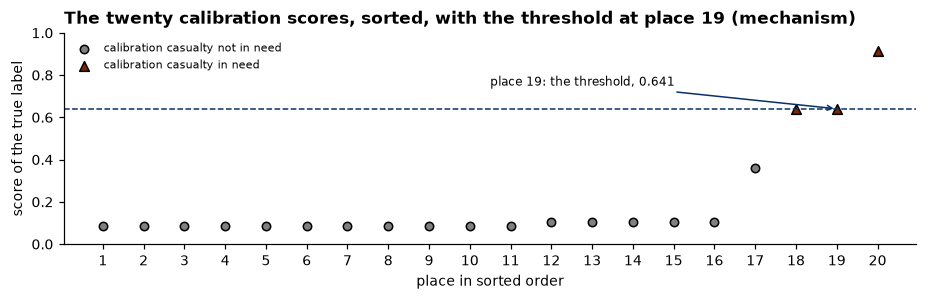

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 2.8))
order = np.argsort(scores, kind="stable")
sorted_scores = np.array(scores)[order]
in_need = cal["needs an intervention"].to_numpy()[order]
ax.scatter(np.arange(1, 21)[~in_need], sorted_scores[~in_need], color="grey", edgecolor="black", s=30,
           label="calibration casualty not in need")
ax.scatter(np.arange(1, 21)[in_need], sorted_scores[in_need], marker="^", color=DARK, edgecolor="black", s=40,
           label="calibration casualty in need")
ax.axhline(q, color=MID, linestyle="--", linewidth=1)
ax.annotate(f"place {rank}: the threshold, {q:.3f}", (rank, q), xytext=(10.5, 0.75), fontsize=8,
            arrowprops={"arrowstyle": "->", "color": MID})
ax.set_xticks(range(1, 21))
ax.set_xlabel("place in sorted order")
ax.set_ylabel("score of the true label")
ax.set_ylim(0, 1)
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_title("The twenty calibration scores, sorted, with the threshold at place 19 (mechanism)", loc="left")
plt.tight_layout()
plt.show()

That is the whole method. Written as notation: with scores $s_1 \le \dots \le s_n$ the threshold is $\hat q = s_{(\lceil (n+1)(1-\alpha) \rceil)}$ and the set is $\{y : s(x, y) \le \hat q\}$. Here every Priority 1 casualty gets both labels, because a probability near one third is not sure either way, and every Priority 2 or 3 casualty gets "no need".

## Diagnosis: triage that says how sure it is

**The answer to the hook.** The trial's difference of 2 points (-4 to 8) could not be told from no difference, while the model alone scored 16 points above the physicians without it (2 to 30) (E-110). Whatever the model could do on those vignettes did not pass to the physicians who had it. The reading that the join, not either part, is where the value was lost is the notebook's own; the trial reports the figures, on vignettes and not patients. Every join in this repository deserves the same suspicion.

One join can be built cheaply: between a triage model and the person who reads it, by giving a set instead of one answer. Below, the MPTT-24 under the figure reading and lens 04's single tree are each wrapped in this way. Each is calibrated at a level of 0.90 on 1,000 further synthetic casualties (seed 11) and scored on the 100,000 of the evaluation sample (seed 42), which neither the models nor the calibration saw. The MPTT-24 gives a priority, not a probability; its probability is the share in need at that priority on lens 02's training sample.

In [6]:
res = hybrids.diagnosis_results()
rows = []
for model in hybrids.MODELS:
    for group in ("all", "battle"):
        m = res[model][group]
        rows.append({"model": model, "casualties": "every stream" if group == "all" else "battle casualties alone",
                     "threshold": res[model]["threshold"], "coverage": m["coverage"], "holding both labels": m["both"],
                     "mean set size": m["size"], "sensitivity, set holds need": m["sensitivity"],
                     "specificity, set holds need": m["specificity"]})
display(pd.DataFrame(rows).set_index(["model", "casualties"]).round(3))
sp = hybrids.spread()
for model in hybrids.MODELS:
    print(f"{model}: across 20 further samples, each calibrated afresh, coverage on every stream runs "
          f"{hybrids.spread_range(f'coverage: {model}')}; among the battle casualties alone, "
          f"{hybrids.spread_range(f'coverage, battle: {model}')}")
print(f"single tree's coverage less the MPTT-24's, on every stream: "
      f"{hybrids.spread_words(100 * (sp['coverage: single tree'] - sp['coverage: MPTT-24 (figure)']))}")
print(thread.rule_on_both("The MPTT-24's figures here are"))

threshold  coverage  \
model            casualties                                     
MPTT-24 (figure) every stream                 0.641     0.933   
                 battle casualties alone      0.641     0.813   
single tree      every stream                 0.662     0.912   
                 battle casualties alone      0.662     0.750   

                                          holding both labels  mean set size  \
model            casualties                                                    
MPTT-24 (figure) every stream                           0.279          1.279   
                 battle casualties alone                0.445          1.445   
single tree      every stream                           0.175          1.175   
                 battle casualties alone                0.348          1.348   

                                          sensitivity, set holds need  \
model            casualties                                             
MPTT-24 (figure) every stream                                   0.600   
                 battle casualties alone                        0.627   
single tree      every stream                                   0.471   
                 battle casualties alone                        0.502   

                                          specificity, set holds need  
model            casualties                                            
MPTT-24 (figure) every stream                                   0.786  
                 battle casualties alone                        0.739  
single tree      every stream                                   0.884  
                 battle casualties alone                        0.808

MPTT-24 (figure): across 20 further samples, each calibrated afresh, coverage on every stream runs from 0.931 to 0.935 across 20 seeds; among the battle casualties alone, from 0.808 to 0.816 across 20 seeds
single tree: across 20 further samples, each calibrated afresh, coverage on every stream runs from 0.888 to 0.914 across 20 seeds; among the battle casualties alone, from 0.676 to 0.756 across 20 seeds
single tree's coverage less the MPTT-24's, on every stream: lower: the difference runs from -4.5 to -2.0 points across 20 seeds
The MPTT-24's figures here are on every stream of the military cohort, disease included, and, where they say so, on battle casualties alone; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). Battle casualties are among the injured; of them alone 50.2% need a lif

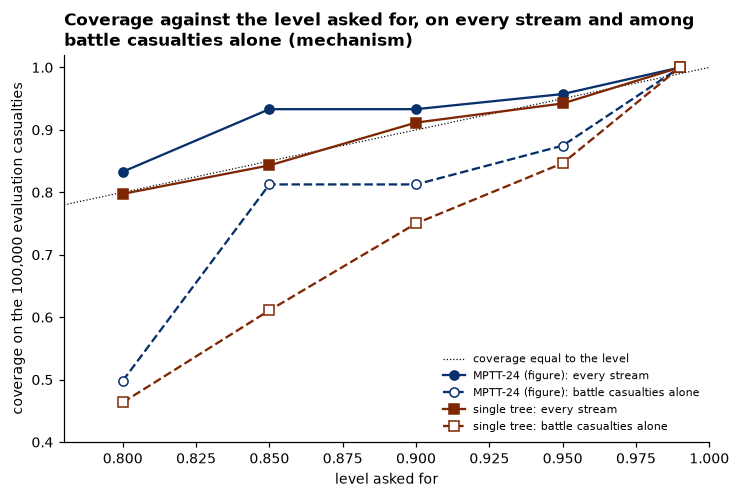

In [7]:
levels = hybrids.level_table()
fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.plot([0.78, 1.0], [0.78, 1.0], color="black", linewidth=0.8, linestyle=":", label="coverage equal to the level")
for model, colour, marker in ((hybrids.RULE, MID, "o"), (hybrids.TREE, DARK, "s")):
    t = levels[levels["model"] == model]
    ax.plot(t["level"], t["coverage"], marker=marker, color=colour, label=f"{model}: every stream")
    ax.plot(t["level"], t["coverage, battle"], marker=marker, color=colour, linestyle="--", markerfacecolor="white",
            label=f"{model}: battle casualties alone")
ax.set_xlabel("level asked for")
ax.set_ylabel("coverage on the 100,000 evaluation casualties")
ax.set_xlim(0.78, 1.0)
ax.set_ylim(0.4, 1.02)
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("Coverage against the level asked for, on every stream and among\nbattle casualties alone (mechanism)",
             loc="left")
plt.tight_layout()
plt.show()

At the level of 0.90, on every stream both sets hold the truth for more casualties than the level asks: the scores take only a few values, so the threshold lands on one of them and the sets come out wider than they need to be. The MPTT-24's sets are the rule itself with Priority 1 read as "need or no need: look again", so flagging those whose set holds need is exactly the rule's Priority 1, with the same sensitivity and specificity. Neither model's sets say "need" alone at this level. Every probability of need the tree gives, its highest leaf's included, is below the threshold, so every set holds "no need": its four leaves with the highest probability of need give "need or no need", and the rest "no need" alone.

Among battle casualties alone, half of whom need an intervention, both sets fall below the level. The level is an average over every stream, and the largest stream, disease admissions, rarely needs an intervention and is mostly called right; the level was never a promise for the battle casualties, and they are where the sets miss. Across 20 calibration sets of 1,000, the tree's coverage on every stream also lands a little below the level on some samples: the guarantee is an average over calibration sets as well as casualties. Both points are general knowledge about the method, shown here on synthetic casualties.

The method has barely reached the clinic: a review found 14 clinical applications, scattered and rarely involving clinicians (E-113). What is built here is a demonstration on synthetic casualties, not established practice.

**Two more joins in diagnosis.** *An ontology feeding a ranking.* Among 4,660 participants, clinical features were coded as terms of an ontology and then put through sequencing with automated prioritisation; about 25% of probands received a diagnosis, 35% where a single-gene cause was likely against 11% where the cause was complex (E-107). Lens 08's graph is the same shape on a small scale: findings coded as the graph's terms, then candidates ranked by the graph's own count, with every edge carrying its source. *Rules generating data for a learner.* DDXPlus holds about 1.3 million synthetic patients with 49 pathologies, generated from a proprietary knowledge base and a commercial rule-based system (E-51). This repository's generator is the same kind of join: a graph of assumed and published parameters generates the casualties, and lenses 02, 04 and 06 learn from them. A learner can at best recover the structure that made its data, which is why every result on the generator is labelled a mechanism (D-8).

## Treatment: joins that carry their doubt, and joins that drop it

This section is about treatment decisions; its results are kept apart from the diagnosis results above. It is a weak fit: prediction sets are a diagnostic tool, and here the notebook looks at how two treatment joins handle uncertainty.

**A test feeding a rule.** The ABC score counts four yes-or-no items, one of them a positive scan, and activates massive transfusion at a score of 2 or more; among 596 patients, of whom 12.4% were massively transfused, that was 75% sensitive and 86% specific (E-31). The register does not describe those patients as military. Lens 03 turns the same positive scan into a belief that the casualty is bleeding into the abdomen, starting from notebook 03's assumed prior of 0.20. Before hospital the scan's accuracy comes from one civilian helicopter service (E-16), and using it for a military casualty is an assumption; in hospital it is an assumption centred on pooled in-hospital figures (E-14). The table gives the belief in each setting. The score counts both as one item.

On the generator's battle casualties the score is scored against significant bleeding, which stands in for the need for transfusion, with small arms injuries counted as penetrating, both assumptions as in lens 01.

,belief after a positive scan,interval low,interval high,what the score counts,ABC score sensitivity,ABC score specificity
setting,,,,,,
scan before hospital,0.654,0.478,0.817,one item,0.239,0.940
scan in hospital,0.903,0.824,0.961,one item,0.315,0.948


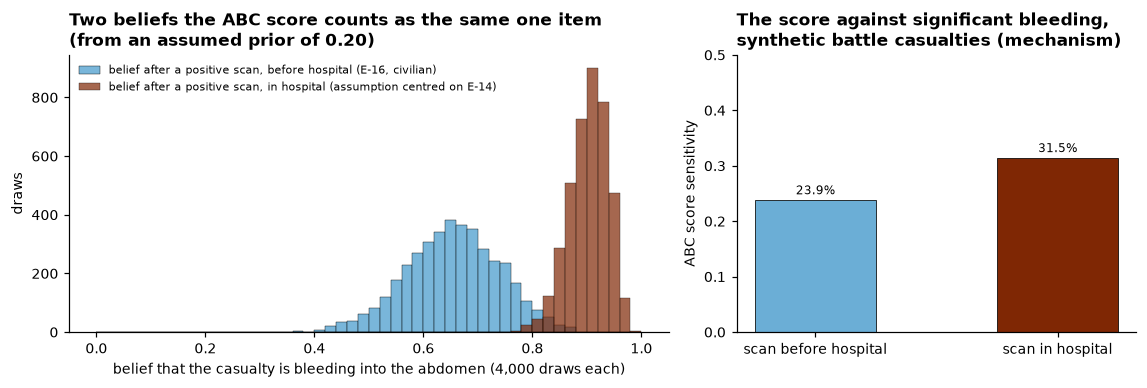

In [8]:
joins = hybrids.scan_into_rule()
display(joins.set_index("setting").round(3))
point = hybrids.point_across_join()
inside = bayesian.belief_after_scan(hybrids.PRIOR, "in_hospital")
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
bins = np.linspace(0, 1, 51)
ax.hist(point["draws"], bins=bins, color=PALE, edgecolor="black", linewidth=0.3, alpha=0.9,
        label="belief after a positive scan, before hospital (E-16, civilian)")
ax.hist(inside.draws, bins=bins, color=DARK, edgecolor="black", linewidth=0.3, alpha=0.7,
        label="belief after a positive scan, in hospital (assumption centred on E-14)")
ax.set_xlabel("belief that the casualty is bleeding into the abdomen (4,000 draws each)")
ax.set_ylabel("draws")
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_title("Two beliefs the ABC score counts as the same one item\n(from an assumed prior of 0.20)", loc="left")
x = np.arange(len(joins))
bx.bar(x, joins["ABC score sensitivity"], 0.5, color=[PALE, DARK], edgecolor="black", linewidth=0.5)
for i, v in enumerate(joins["ABC score sensitivity"]):
    bx.text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=8)
bx.set_xticks(x, joins["setting"])
bx.set_ylabel("ABC score sensitivity")
bx.set_ylim(0, 0.5)
bx.set_title("The score against significant bleeding,\nsynthetic battle casualties (mechanism)", loc="left")
plt.tight_layout()
plt.show()

**A trial feeding a prior.** STAAMP, a prehospital trial of tranexamic acid against placebo, enrolled 903 patients, 447 and 456; 30-day mortality was 8.1% against 9.9%, a hazard ratio of 0.81 (0.59 to 1.11). A Bayesian reanalysis re-read it under three priors (E-74). With a non-informative prior the posterior ratio was 0.82 (0.52 to 1.23); with a prior from PATCH-Trauma, 0.80 (0.65 to 0.97); with a prior from CRASH-2, 0.91 (0.85 to 0.97). CRASH-2 randomised 20,211 civilian trauma patients within 8 hours of injury in 274 hospitals in 40 countries (E-19). Nothing is discarded in this join, but an assumption is added: that the earlier trial's patients are like the later trial's. The register records no population for STAAMP or PATCH-Trauma beyond the numbers above.

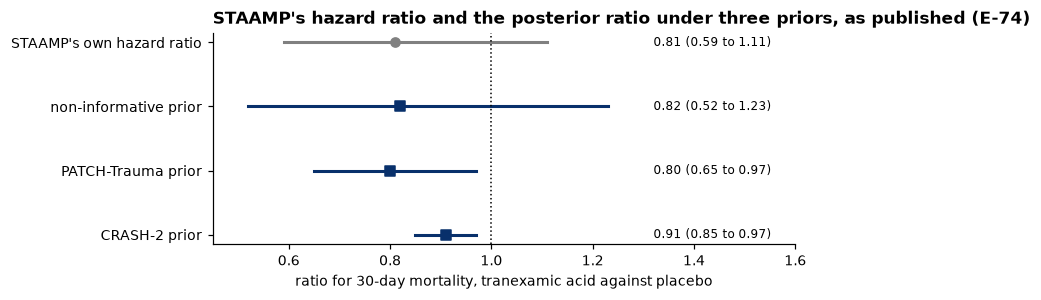

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
rows = [("STAAMP's own hazard ratio", *hybrids.STAAMP["hazard ratio"])] + list(hybrids.STAAMP_POSTERIORS)
for i, (name, mid, lo, hi) in enumerate(rows):
    y = len(rows) - 1 - i
    ax.plot([lo, hi], [y, y], color=MID if i else "grey", linewidth=2)
    ax.scatter(mid, y, color=MID if i else "grey", marker="s" if i else "o", zorder=3)
    ax.text(1.32, y, f"{mid:.2f} ({lo:.2f} to {hi:.2f})", va="center", fontsize=8)
ax.axvline(1, color="black", linestyle=":", linewidth=1)
ax.set_yticks(range(len(rows)), [r[0] for r in rows][::-1])
ax.set_xlim(0.45, 1.6)
ax.set_xlabel("ratio for 30-day mortality, tranexamic acid against placebo")
ax.set_title("STAAMP's hazard ratio and the posterior ratio under three priors, as published (E-74)", loc="left")
plt.tight_layout()
plt.show()

## The failures: a guarantee that does not travel, a set that says nothing, a point that hides its doubt

**Coverage lost when the mix shifts.** The sets were calibrated on the default mix, in which disease admissions are the largest stream. Below, the same sets are scored on 100,000 new casualties from mixes with more and more battle casualties, the rest split between disease and non-battle injury as in the default mix; each mix is an assumption. That calibration cases must resemble new ones is general knowledge about the method, stated here, not a finding of E-112.

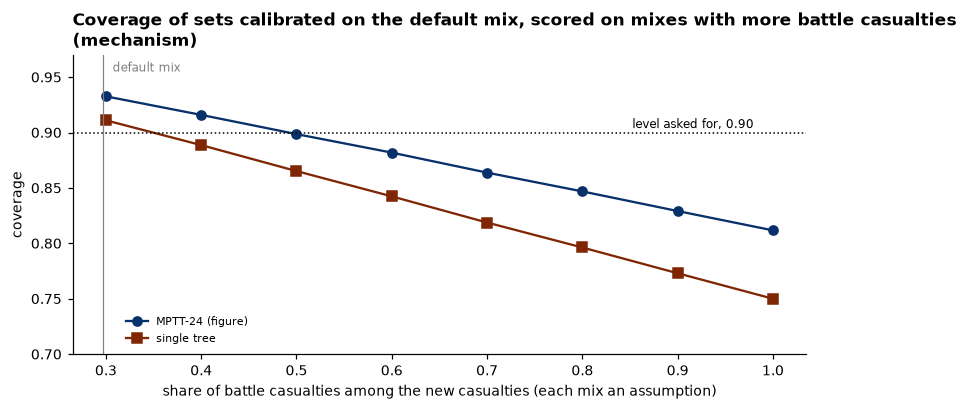

MPTT-24 (figure), new casualties 80% battle: across 20 further samples coverage runs from 0.846 to 0.850 across 20 seeds
single tree, new casualties 80% battle: across 20 further samples coverage runs from 0.737 to 0.801 across 20 seeds


In [10]:
curve = hybrids.shift_curve()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for model, colour, marker in ((hybrids.RULE, MID, "o"), (hybrids.TREE, DARK, "s")):
    t = curve[curve["model"] == model]
    ax.plot(t["battle share"], t["coverage"], marker=marker, color=colour, label=model)
ax.axhline(hybrids.LEVEL, color="black", linestyle=":", linewidth=1)
ax.text(0.98, hybrids.LEVEL + 0.004, f"level asked for, {hybrids.LEVEL:.2f}", fontsize=8, ha="right")
default_battle = thread.stream_shares()["battle"] / sum(thread.stream_shares().values())
ax.axvline(default_battle, color="grey", linewidth=0.8)
ax.text(default_battle + 0.01, 0.955, "default mix", fontsize=8, color="grey")
ax.set_xlabel("share of battle casualties among the new casualties (each mix an assumption)")
ax.set_ylabel("coverage")
ax.set_ylim(0.7, 0.97)
ax.legend(fontsize=7, frameon=False, loc="lower left", bbox_to_anchor=(0.06, 0))
ax.set_title("Coverage of sets calibrated on the default mix, scored on mixes with more battle casualties\n"
             "(mechanism)", loc="left")
plt.tight_layout()
plt.show()
sp = hybrids.spread()
for model in hybrids.MODELS:
    print(f"{model}, new casualties {hybrids.SHIFTED['battle']:.0%} battle: across 20 further samples coverage runs "
          f"{hybrids.spread_range(f'coverage, shifted: {model}')}")

In [11]:
always = hybrids.every_label()
rows = [{"set": f"on the {m}", "coverage": always["sets"][m]["coverage"], "holding both labels": always["sets"][m]["both"],
         "net benefit per 100 at 0.10": 100 * decision.net_benefit(hybrids.flags(m, observed), need,
                                                                             decision.threshold())}
        for m in hybrids.MODELS]
rows.append({"set": "always both labels", "coverage": always["coverage"], "holding both labels": always["both"],
             "net benefit per 100 at 0.10": always["net benefit"]})
rows.append({"set": "(flag every casualty)", "coverage": float("nan"), "holding both labels": float("nan"),
             "net benefit per 100 at 0.10": always["flag every casualty"]})
pd.DataFrame(rows).set_index("set").round(3)

,coverage,holding both labels,net benefit per 100 at 0.10
set,,,
on the MPTT-24 (figure),0.933,0.279,8.037
on the single tree,0.912,0.175,6.800
always both labels,1.000,1.000,7.449
(flag every casualty),NaN,NaN,7.449


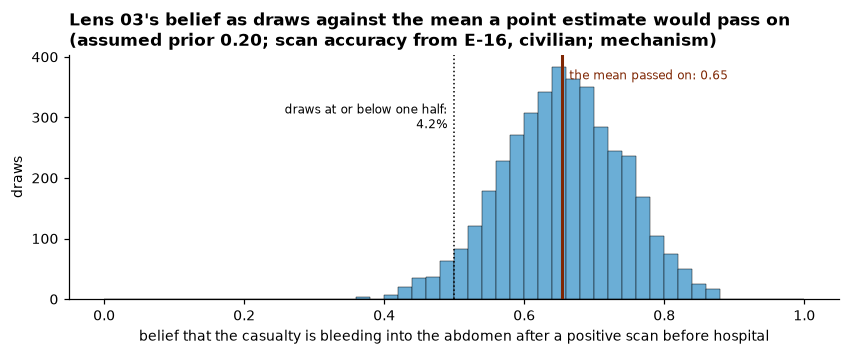

In [12]:
fig, ax = plt.subplots(figsize=(7.8, 3.3))
ax.hist(point["draws"], bins=np.linspace(0, 1, 51), color=PALE, edgecolor="black", linewidth=0.3)
ax.axvline(point["line"], color="black", linestyle=":", linewidth=1)
ax.axvline(point["mean"], color=DARK, linewidth=2)
ax.text(point["mean"] + 0.01, ax.get_ylim()[1] * 0.9, f"the mean passed on: {point['mean']:.2f}", color=DARK, fontsize=8)
ax.text(point["line"] - 0.01, ax.get_ylim()[1] * 0.7, f"draws at or below one half:\n{point['below half']:.1%}",
        ha="right", fontsize=8)
ax.set_xlabel("belief that the casualty is bleeding into the abdomen after a positive scan before hospital")
ax.set_ylabel("draws")
ax.set_title("Lens 03's belief as draws against the mean a point estimate would pass on\n"
             "(assumed prior 0.20; scan accuracy from E-16, civilian; mechanism)", loc="left")
plt.tight_layout()
plt.show()

**A set that is always every label.** A set holding both labels for every casualty is always right and says nothing. Its coverage is 100%; read as a flag, it flags every casualty, so its net benefit at 0.10 is exactly that of flagging every casualty. Coverage alone cannot tell a useful set from a useless one; the share of sets holding both labels, and what a decision does with them, can.

**A point estimate passed across a join.** If lens 03 passed lens 10 its mean belief after a positive scan before hospital, a decision to evacuate first at a belief above one half, an assumption as in notebook 03, would be taken with no doubt at all. The draws say that for a share of the plausible values of the scan's accuracy the belief is at or below one half. Carrying the belief as draws (E-70; D-19) is what stops a join from inventing certainty.

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label. Axes 3, 4 and 5 are stated. Axis 7 is net benefit at a threshold of 0.10 for every lens (D-26), with a miss weighed nine times a false alarm, an assumption; here a casualty is flagged when its set holds need. The baseline is the MPTT-24 read as its figure was published, with the text reading beside it, labelled as validated (D-24). The diagnosis columns are scored on all 100,000 synthetic casualties of the military cohort, disease included, with the battle casualties alone wherever coverage falls there. Across 20 further samples, each calibrated afresh, the table gives the spread of each set's coverage, of its coverage among the battle casualties alone less that on every stream, of the tree's coverage less the rule's, and of each flag's net benefit less the MPTT-24's (figure). The treatment column is the join of a test into a rule, a weak fit. Fit is native for diagnosis: a set is a triage answer.

In [13]:
with pd.option_context("display.max_colwidth", None):
    display(hybrids.seven_axes())
print(baseline.died_before_care_note(baseline.died_before_care_count(observed, truth),
                                     "the 100,000 casualties behind the diagnosis and baseline columns"))

,diagnosis: sets on the MPTT-24 (figure),diagnosis: sets on the single tree,"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)",treatment: the ABC score fed by the scan (a join)
axis,,,,,
1 Discrimination (mechanism),"sensitivity 60.0%, specificity 78.6%, flagging a casualty whose set holds need; coverage 93.3% at a level of 90%, 27.9% of sets holding both labels; all 100,000 synthetic casualties of the military cohort, disease included. Across 20 further samples, each calibrated afresh, coverage runs from 93.1 to 93.5 per cent across 20 seeds; its sensitivity is identical to the MPTT-24's (figure) on every one of the 20 samples. The flag is the MPTT-24's Priority 1 itself: only a Priority 1 casualty's set holds need","sensitivity 47.1%, specificity 88.4%, flagging a casualty whose set holds need; coverage 91.2% at a level of 90%, 17.5% of sets holding both labels; all 100,000 synthetic casualties of the military cohort, disease included. Across 20 further samples, each calibrated afresh, coverage runs from 88.8 to 91.4 per cent across 20 seeds; its sensitivity less the MPTT-24's (figure) is lower: the difference runs from -27.5 to -12.2 points across 20 seeds; its coverage less the rule's is lower: the difference runs from -4.5 to -2.0 points across 20 seeds","sensitivity 60.0%, specificity 78.6%. The scorecard's figures are on every stream of the military cohort, disease included; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).","sensitivity 61.4%, specificity 77.8%","ABC score: sensitivity 23.9%, specificity 94.0% against significant bleeding, battle casualties, scan before hospital, the positive scan behind its item a belief of 65.4% from notebook 03's assumed prior of 0.20 and the scan's accuracy in one civilian helicopter service (E-16), an assumption for a military casualty"
2 Calibration (mechanism),"Coverage 93.3% against a level of 90% on every stream; among the battle casualties alone 81.3%, below the level: across 20 further samples their coverage less that on every stream is lower: the difference runs from -12.3 to -11.8 points across 20 seeds. Mean set size 1.279 labels. The model beneath: Brier 0.125, where lower is better; mean probability minus share in need +0.001","Coverage 91.2% against a level of 90% on every stream; among the battle casualties alone 75.0%, below the level: across 20 further samples their coverage less that on every stream is lower: the difference runs from -21.2 to -15.8 points across 20 seeds. Mean set size 1.175 labels. The model beneath: Brier 0.117, where lower is better; mean probability minus share in need -0.000","A single label, right for 75.5% of casualties (Brier 0.245, the share misclassified, where lower is better); share flagged minus share in need +0.112","A single label, right for 75.1% of casualties (Brier 0.249, the share misclassified, where lower is better); share flagged minus share in need +0.121","The score gives no probability: Brier 0.314, the share misclassified, where lower is better"
3 Uncertainty expressed,"A set of one label or two, holding the true label for at least the level on average over casualties like the calibration ones","The same, from the tree's probability",None: a priority,None: a priority,None: a count of items; the belief behind the scan item is dropped
4 What it needed,"The rule, the share in need at each priority from 100,000 labelled synthetic casualties, and 1,000 more labelled casualties to calibrate (mechanism)","The tree, fitted on 100,000 labelled synthetic casualties, and 1,000 more to calibrate (mechanism)",Rules only at the point of use (E-08),Rules only at the point of use (E-08),Rules and a scan at the point of use (E-31)
5 Readability,"A medic reads the MPTT-24 as published, with Priority 1 read as '

482 of the 100,000 casualties behind the diagnosis and baseline columns died from bleeding before pre-hospital care in the generator, without tranexamic acid, and are included


In [14]:
card = pd.DataFrame([vars(row) for row in hybrids.LENS.scorecard()])
with pd.option_context("display.max_colwidth", None):
    display(card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]])

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"coverage, the share whose set holds the true label, prediction sets on the MPTT-24 (figure) at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.933,0.755,mechanism,native,generator
1,diagnosis,"share of sets holding both labels, prediction sets on the MPTT-24 (figure) at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.279,0.000,mechanism,native,generator
2,diagnosis,"sensitivity, flagged where the set holds need, prediction sets on the MPTT-24 (figure) at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.600,0.600,mechanism,native,generator
3,diagnosis,"specificity, flagged where the set holds need, prediction sets on the MPTT-24 (figure) at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.786,0.786,mechanism,native,generator
4,diagnosis,"coverage, the share whose set holds the true label, prediction sets on the single tree at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.912,0.755,mechanism,native,generator
5,diagnosis,"share of sets holding both labels, prediction sets on the single tree at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.175,0.000,mechanism,native,generator
6,diagnosis,"sensitivity, flagged where the set holds need, prediction sets on the single tree at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.471,0.600,mechanism,native,generator
7,diagnosis,"specificity, flagged where the set holds need, prediction sets on the single tree at a level of 0.90, against need for a life-saving intervention, scan before hospital",0.884,0.786,mechanism,native,generator
8,diagnosis,"coverage, the share whose set holds the true label, prediction sets on the MPTT-24 (figure) at a level of 0.90, against need for a life-saving intervention, scan in hospital",0.933,0.755,mechanism,native,generator
9,diagnosis,"share of sets holding both labels, prediction sets on the MPTT-24 (figure) at a level of 0.90, against need for a life-saving intervention, scan in hospital",0.279,0.000,mechanism,native,generator


**The lens table.** Every lens's scorecard rows, set side by side. The table is generated by the library from each lens's `scorecard()`; no number in it is typed here. The baseline column is each lens's own comparison, for most of them the MPTT-24 under the figure reading; read each metric's wording before setting two rows against each other, because the lenses do not all score the same target. The same table, with a diagnosis and treatment toggle, is page 3 of the app.

In [15]:
display(thread.lens_summary())
with pd.option_context("display.max_rows", 300, "display.max_colwidth", None):
    for case in ("diagnosis", "treatment"):
        print(f"{case} rows of every lens's scorecard")
        display(thread.lens_table(case))
print(thread.lens_table_rule())

,diagnosis rows,diagnosis fit,treatment rows,treatment fit,labels,data
lens,,,,,,
MPTT-24,8,native,0,no row,mechanism,generator
Bayesian,8,native,1,weak,mechanism,"fixture:crash3.csv, generator"
Causal inference,16,weak,4,native,mechanism,generator
Connectionist,4,native,8,weak,mechanism,"constructed images, generator"
Decision theory,8,weak,2,native,mechanism,generator
Frequentist,8,native,1,weak,mechanism,"fixture:crash2.csv, generator"
Hybrids: prediction sets,16,native,6,weak,mechanism,generator
Knowledge graph,14,native,9,native,mechanism,generator
Reinforcement learning,8,weak,4,native,mechanism,"constructed decision process, generator"


diagnosis rows of every lens's scorecard


,lens,metric,value,baseline,label,fit,data
0,MPTT-24,"sensitivity, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan before hospital",0.5999,0.5999,mechanism,native,generator
1,MPTT-24,"specificity, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan before hospital",0.7856,0.7856,mechanism,native,generator
2,MPTT-24,"Brier score, where lower is better, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan before hospital",0.2454,0.2454,mechanism,native,generator
3,MPTT-24,"share flagged minus share in need, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan before hospital",0.1118,0.1118,mechanism,native,generator
4,MPTT-24,"sensitivity, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan in hospital",0.5999,0.5999,mechanism,native,generator
5,MPTT-24,"specificity, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan in hospital",0.7856,0.7856,mechanism,native,generator
6,MPTT-24,"Brier score, where lower is better, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan in hospital",0.2454,0.2454,mechanism,native,generator
7,MPTT-24,"share flagged minus share in need, Priority 1 against need for a life-saving intervention, generator physiology tuned to accuracy measured on hospital observations, scan in hospital",0.1118,0.1118,mechanism,native,generator
8,Bayesian,"sensitivity, belief above one half, before hospital, against bleeding into the abdomen: the belief is in it and the observed share is the share with it, among battle casualties alone",0.0475,0.5773,mechanism,native,generator
9,Bayesian,"specificity, belief above one half, before hospital, against bleeding into the abdomen: the belief is in it and the observed share is the share with it, among battle casualties alone",0.9983,0.5782,mechanism,native,generator


treatment rows of every lens's scorecard


,lens,metric,value,baseline,label,fit,data
0,Bayesian,"probability tranexamic acid reduces head injury death on the synthetic fixture under the prior from CRASH-2, a civilian trial: a figure that reflects the prior, since the fixture's rows are random and the prior alone gives nearly the same",0.9978,none stated,mechanism,weak,fixture:crash3.csv
1,Causal inference,"true effect of tranexamic acid, with less without, battle casualties alive at pre-hospital care, under the constructed allocation, deaths from bleeding per 100",-1.4604,none stated,mechanism,native,generator
2,Causal inference,"estimate less the true effect: naive, battle casualties alive at pre-hospital care, under the constructed allocation, deaths from bleeding per 100",5.0348,none stated,mechanism,native,generator
3,Causal inference,"estimate less the true effect: adjusted for every variable the allocation uses, battle casualties alive at pre-hospital care, under the constructed allocation, deaths from bleeding per 100",-0.1468,none stated,mechanism,native,generator
4,Causal inference,"estimate less the true effect: adjusted on the recorded signs alone, battle casualties alive at pre-hospital care, under the constructed allocation, deaths from bleeding per 100",2.5788,none stated,mechanism,native,generator
5,Connectionist,"sensitivity, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.6925,0.5999,mechanism,weak,generator
6,Connectionist,"specificity, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.7865,0.7856,mechanism,weak,generator
7,Connectionist,"Brier score, where lower is better, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.1080,0.2454,mechanism,weak,generator
8,Connectionist,"mean probability minus share in need, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.0029,0.1118,mechanism,weak,generator
9,Connectionist,"sensitivity, network on the signs against need for a life-saving intervention, every stream, scan in hospital",0.6925,0.5999,mechanism,weak,generator


The MPTT-24's figures in these tables are on every stream of the military cohort, disease included, except in the diagnosis rows of Bayesian, Causal inference and Stochastic processes and the treatment rows of Rules, Hybrids: prediction sets, Decision trees and Decision theory, where they are on battle casualties alone or a group within them; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).


**Described, not built.** Two further joins are described here and built elsewhere, in two separate projects, POLYBIUS and ARIADNE (D-11). Retrieval-augmented generation puts a store of curated documents in front of a language model, so that what the model says is drawn from sources someone keeps: on 314 clinical questions in nine specialties, rated by ten clinicians, a retrieval-augmented model was rated significantly better than standard models on factuality, completeness, preference and safety, with no effect sizes in the abstract (E-111). Graph learning learns from the structure of a graph such as lens 08's instead of retrieving from it. Neither is built in this repository.

## The brain analogy, and where it breaks

**What it resembles.** Complementary learning systems: the hippocampus stores single episodes fast, the neocortex learns structure slowly, and replay protects old knowledge; a 2016 update adds that cortical learning can be fast when new information fits prior knowledge (E-57). Retrieval joined to a trained model has the same shape: a fast store of specific cases beside a slow learner of the general pattern. A schematic model of diagnosis as two systems, one intuitive and one analytical, has both outputs pass through a calibration step before a diagnosis is reached (E-54): a join between a fast and a slow system in the source's own schematic, and the step a prediction set makes explicit.

**Where it breaks.** E-57 is a model of two brain systems, not of any clinical tool, and nothing in this notebook shows that a system built in that shape behaves like a brain. Nor is the fast mode the faulty one: a review found the intuitive mode no more prone to error than the deliberate one, and prompting the use of both reduced error (E-53). The set built here is calibrated by counting synthetic casualties, not by anything a clinician does.